### Práctica 2: Localización de un robot con diferentes sensores

En esta práctica vamos a trabajar en un problema muy común en la robótica: la localización de un robot móvil empleando la información de sus sensores.

Los robots móviles pueden disponer de varias fuentes de información para localizarse en su entorno:

- **Receptores GNSS** (Global Navigation Satellite System, Sistema Global de Navegación por Satélite): reciben señales de constelaciones de satélites (GPS, Galileo o GLONASS) y las utilizan para triangular su posición sobre el globo terrestre (latitud, longitud y altitud). Es el sistema más utilizado para la localización de robots en escenarios exteriores, pero no suele estar disponible en interiores. Además, en escenarios con una densidad considerable de obstáculos (por ejemplo, un valle entre montañas o una ciudad con edificios altos), se puede ver afectado por la falta de cobertura o por señales rebotadas. En la práctica, esto se traduce en medidas ruidosas y, ocasionalmente, outliers (medidas erróneas).

- **IMU** (Inertial Measurement Unit, Unidad de Medida Inercial): combina acelerómetros, giroscopios y magnetómetros para determinar la aceleración, velocidad angular y orientación del robot. La integración de estas medidas permite obtener la posición y orientación. Sin embargo, estos sistemas presentan tanto ruidos como derivas, y la integración de estos errores los hace crecer con el tiempo. En la práctica, esto se traduce en sesgos que se acumulan y hacen que la posición estimada se desvíe progresivamente de la real.

- **Odometría**: permite estimar la posición del robot a partir de las medidas de sus encoders, unos sensores que miden el desplazamiento y velocidad de sus ruedas. Fenómenos como el deslizamiento de las ruedas pueden dar lugar a derivas que separen progresivamente la posición estimada de la real. En la práctica, esto se traduce en errores de escala y ruido que también se acumulan.

Todas estas fuentes tienen sus fortalezas y debilidades:

| Sensor | Frecuencia | Precisión a corto plazo | Precisión a largo plazo | Disponibilidad |
|--------|------------|-------------------------|-------------------------|----------------|
| GNSS | Baja (1-10 Hz) | Media	| Alta | Solo exterior |
| IMU | Alta (100-200 Hz) | Alta | Baja (deriva) | Cualquiera |
| Encoders | Alta (50-100 Hz) | Alta | Baja (deriva) | Cualquiera |

Por ello, se suelen combinar para una localización más precisa e incluso reforzar con técnicas de localización en mapas. Este es el caso del algoritmo SLAM (Simultaneous Location And Mapping), que localiza al robot en un mapa conocido a partir de la información de sus sensores sobre su entorno (escáneres láser, cámaras RGBD, sensores ultrasónicos e infrarrojos...). 

El objetivo de esta práctica es fusionar las tres fuentes para obtener una estimación de la posición del robot que sea mejor que cualquiera de ellas por separado. Para ello, vamos a trabajar con datos reales de trayectorias de un robot móvil, simular las medidas de cada sensor con sus errores característicos, e implementar dos técnicas de fusión: el filtro de Kalman y el filtro de partículas.

#### Organización de los archivos:

Los archivos de la práctica se organizan de la siguiente manera:

- *practice.ipynb*: 
    - TODO: Aquí tienes que implementar los filtros y analizar su rendimiento. 
- *path_generator.ipynb*: 
    - Genera varias rutas reales del robot para probar los filtros desarrollados.
    - TODO: Aquí puedes generar tus propias rutas.
- *src/sensor_simulator.py*: 
    - Simula las medidas de los sensores a partir de las rutas reales del robot.
    - Funciones relevantes: 
        - *sim_sensors(df_gt)*: Genera las medidas de los sensores.
- src/utils.py: 
    - Contiene métodos para mostrar gráficamente los resultados de los filtros.
    - Funciones relevantes: 
        - *load_path(name)*: Carga una ruta a partir de un archivo CSV.
        - *plot_path(gt, estimates)*: Dibuja las rutas real y estimada.
        - *plot_error(gt, estimates)*: Dibuja el error de la ruta estimada frente a la real.
- src/metrics.py:
    - Contiene métodos para calcular los errores de estimación de los filtros.
    - Funciones relevantes:
        - *summary_metrics(estimate, ground_truth)*: Calcula errores RMSE, ATE y RPE.

#### Entrega de la práctica:
Entrega: Carpeta comprimida con nombre Apellido1_Apellido2_Nombre.zip

Fecha: 24/11/2026 - 23:59

Contacto: juan.roldan@uam.es

In [1]:
import numpy as np
import sys
sys.path.append('src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from utils import load_path, plot_path, plot_error
from sensor_simulator import SensorSimulator
from metrics import summary_metrics

### Ejercicio 1: Filtro de Kalman para GPS

Vamos a comenzar con un modelo sencillo de velocidad constante.

En este modelo, el estado del robot se representa mediante el vector: 

$$\mathbf{x} = [x,    y,    v_{x},  v_{y}]$$

La evolución del estado se describe por el siguiente modelo cinemático:

$$
\begin{aligned}
\dot{x} &= v_{x} \\
\dot{y} &= v_{y} \\
\end{aligned}
$$

Y el filtro de Kalman se aplica sobre la siguiente discretización:

$$
\begin{aligned}
x_{k+1} &= x_k + v_{xk} \Delta t \\
y_{k+1} &= y_k + v_{yk} \Delta t \\
\end{aligned}
$$

A) Implementa un filtro de Kalman que trabaje con las medidas del GPS y un modelo de velocidad constante.

1. Crea la función de predicción, que propaga el estado y la covarianza utilizando un modelo de movimiento.
2. Crea la función de actualización, que corrige el estado empleando la medida del GPS.

In [2]:
class KalmanFilterGPS:
    """
    Filtro de Kalman para GPS
    Estado: [x, y, vx, vy]
    Predicción con modelo de velocidad constante
    Actualización con medidas del GPS
    """
    def __init__(self, dt, sigma_gps=1.5):
        self.dt = dt
        self.sigma_gps = sigma_gps
        
        # Estado inicial
        self.x = np.zeros(4)  # [x, y, vx, vy]
        
        # Covarianza inicial
        self.P = np.eye(4) * 10.0
        
        # Matriz de transición
        self.F = np.array([
            [1, 0, dt, 0],
            [0, 1, 0, dt],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ])
        
        # Ruido del proceso
        q = 0.1
        self.Q = q * np.array([
            [dt**3/3, 0, dt**2/2, 0],
            [0, dt**3/3, 0, dt**2/2],
            [dt**2/2, 0, dt, 0],
            [0, dt**2/2, 0, dt]
        ])
        
        # Matriz de medida
        self.H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0]
        ])
        
        # Ruido de medida
        self.R = np.eye(2) * sigma_gps**2
    
    def predict(self):
        """Paso de predicción"""
        # TODO: Implementar
        
        pass
    
    def update(self, z):
        """Paso de actualización"""
        # TODO: Implementar

        pass
    
    def step(self, z_gps):
        """Paso completo"""
        self.predict()
        if z_gps is not None:
            self.update(z_gps)
        return self.x.copy()

B) Compara el error de las medidas brutas del GPS con el del filtro de Kalman. 

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


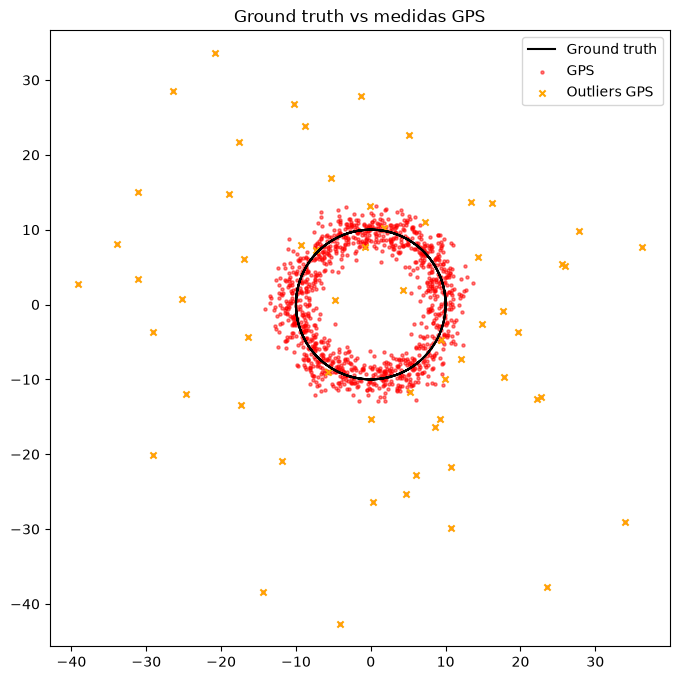

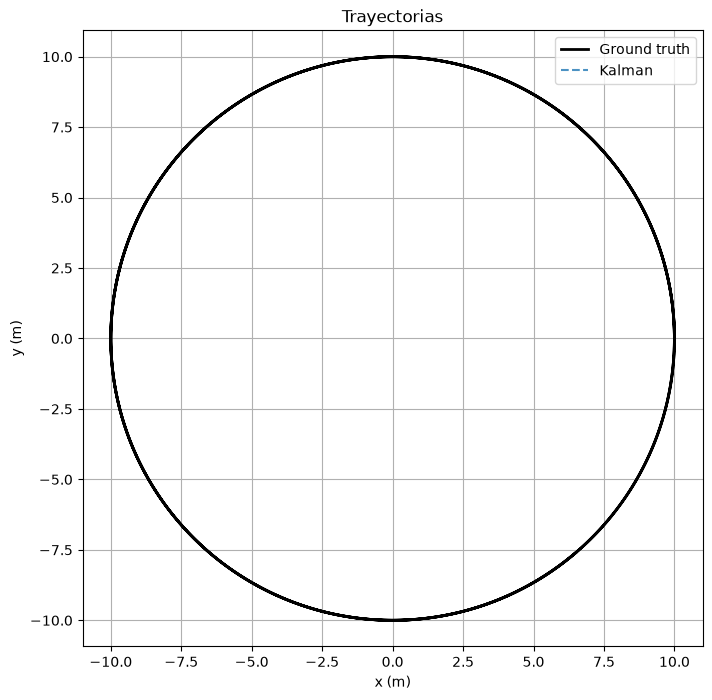

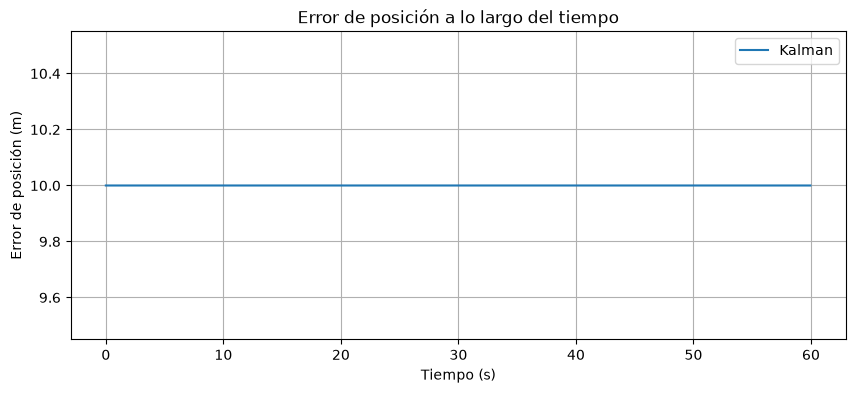

Kalman       RMSE=10.000 m  ATE=9.990 m  RPE=1.499 m


In [3]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular') # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de Kalman
dt = 1.0 / meta['frecuencia_hz']
kalman = KalmanFilterGPS(dt=dt, sigma_gps=1.5)

estimates_kf = np.zeros((len(df_gt), 4))
for i in range(len(df_gt)):
    z = np.array([medidas['gps']['x_gps'].iloc[i], medidas['gps']['y_gps'].iloc[i]])
    estimates_kf[i] = kalman.step(z)

# 5. Representa el resultado
estimates = {'Kalman': estimates_kf}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for name, est in estimates.items():
    m = summary_metrics(est, gt_array, name)
    print(f"{m['name']:12s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza el desempeño del filtro de Kalman. ¿El filtro mejora la señal del GPS? ¿El error es adecuado o excesivo para la tarea? ¿Qué causas puede tener este error? ¿Cómo se podría reducir?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

C) Implementa una nueva función de actualización que no pase los outliers al filtro.

In [7]:
class KalmanFilterGPSwithGating(KalmanFilterGPS):
    
    def update_gating(self, z, threshold=3.0):
        """Solo actualiza si la innovación es razonable."""
        d = 0
        # TODO: Implementar el código
        if d < threshold:
            self.update(z)
    
    def step_gating(self, z_gps):
        """Paso completo"""
        self.predict()
        if z_gps is not None:
            self.update_gating(z_gps)
        return self.x.copy()

D) Compara el error del filtro de Kalman antes y después del gating. 

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


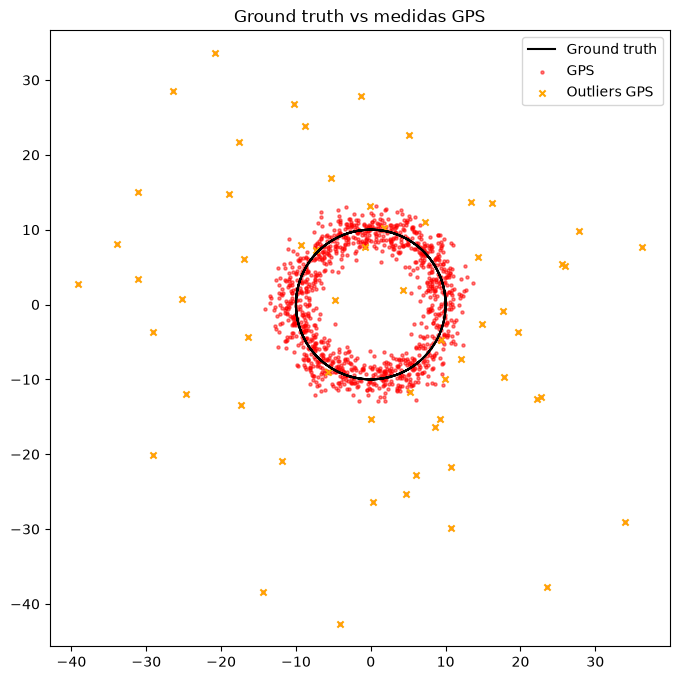

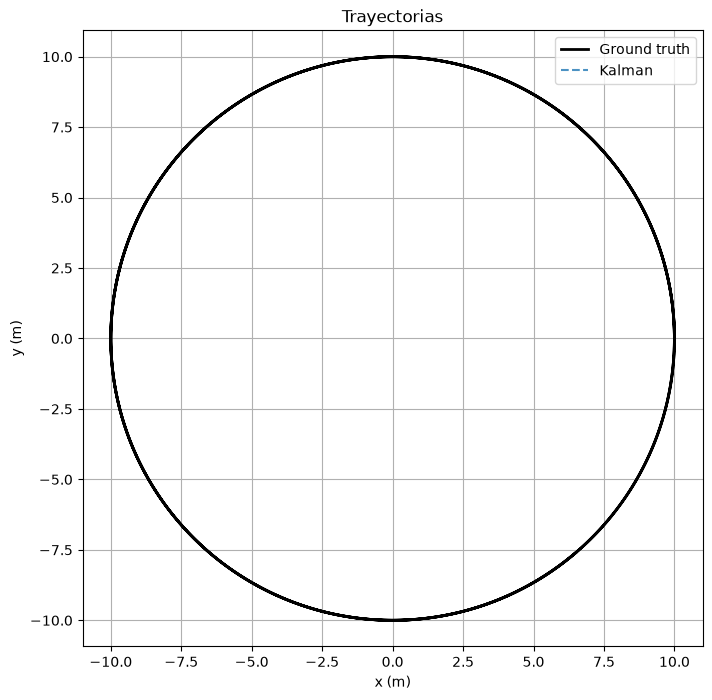

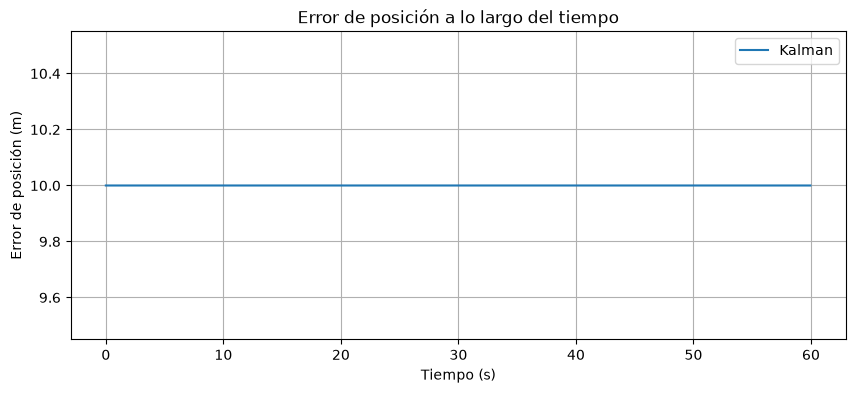

Kalman       RMSE=10.000 m  ATE=9.990 m  RPE=1.499 m


In [8]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular') # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de Kalman
dt = 1.0 / meta['frecuencia_hz']
kalman = KalmanFilterGPSwithGating(dt=dt, sigma_gps=1.5)

estimates_kf = np.zeros((len(df_gt), 4))
for i in range(len(df_gt)):
    z = np.array([medidas['gps']['x_gps'].iloc[i], medidas['gps']['y_gps'].iloc[i]])
    estimates_kf[i] = kalman.step_gating(z)

# 5. Representa el resultado
estimates = {'Kalman': estimates_kf}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for name, est in estimates.items():
    m = summary_metrics(est, gt_array, name)
    print(f"{m['name']:12s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza la mejoría del filtro de Kalman. ¿Cuánto ha decrecido el error al filtrar los outliers? ¿El error es adecuado o excesivo para la tarea? ¿Qué causas puede tener este error? ¿Cómo se podría seguir reduciendo?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

### Ejercicio 2: Filtro de Kalman con GPS, IMU y Encoders 

Ahora vamos a pasar a un modelo de aceleración constante.

En este modelo, el estado del robot se representa mediante el vector: 

$$\mathbf{x} = [x,    y,  \theta, v,  \omega]$$

La evolución del estado se describe por el siguiente modelo cinemático:

$$
\begin{aligned}
\dot{x} &= v \cos\theta \\
\dot{y} &= v \sin\theta \\
\dot{\theta} &= \omega \\
\dot{v} &= a \\
\dot{\omega} &= \alpha
\end{aligned}
$$

Y el filtro de Kalman se aplica sobre la siguiente discretización:

$$
\begin{aligned}
x_{k+1} &= x_k + v_k \cos\theta_k \, \Delta t + \tfrac{1}{2} a_k \cos\theta_k \, \Delta t^2 \\
y_{k+1} &= y_k + v_k \sin\theta_k \, \Delta t + \tfrac{1}{2} a_k \sin\theta_k \, \Delta t^2 \\
\theta_{k+1} &= \theta_k + \omega_k \, \Delta t + \tfrac{1}{2} \alpha_k \, \Delta t^2 \\
v_{k+1} &= v_k + a_k \, \Delta t \\
\omega_{k+1} &= \omega_k + \alpha_k \, \Delta t
\end{aligned}
$$

Los sensores aportan las siguientes medidas para el nuevo modelo:

- GPS: 
    - Posición $[x, y]$: Se puede usar en el paso de actualización como medida directa de la posición.
- IMU: 
    - Aceleración $a_{imu}$: Se puede usar en el paso de predicción para propagar la velocidad y la posición. La medida viene contaminada por un sesgo $b_a$ y un ruido gaussiano $v_a$.
    - Velocidad angular $\omega_{imu}$: Se puede usar en el paso de predicción para propagar la orientación. También tiene un sesgo $b_\omega$ y un ruido $v_{\omega}$.
- Encoders:
    - Desplazamiento $\Delta s_{enc}$: Se puede utilizar para calcular la velocidad en el paso de actualización $v_{enc}= \tfrac{\Delta s_{enc}}{ \Delta t}$
    - Giro $\Delta \theta_{enc}$: Se puede utilizar para calcular la velocidad angular en el paso de actualización $\omega_{enc}= \tfrac{\Delta \theta_{enc}}{\Delta t}$

    A) Implementa un filtro de Kalman que trabaje con las medidas del GPS, la IMU y los Encoders.

In [12]:
class KalmanFilterGPSIMUEncoders:
    """
    Filtro de Kalman para GPS, IMU y Encoders
    Estado: [x, y, theta, v, omega]
    Predicción con modelo de aceleración constante
    Actualización con medidas del GPS, predicción con IMU y Encoders
    """
    def __init__(self, dt, sigma_gps=1.5, sigma_imu_a=0.1, sigma_imu_w=0.02,
                 sigma_enc_v=0.05, sigma_enc_w=0.02):
        self.dt = dt
        self.x = np.zeros(5)  # [x, y, theta, v, omega]
        self.P = np.eye(5) * 1.0
        self.P[0, 0] = 5.0   # posición: más incertidumbre inicial
        self.P[1, 1] = 5.0
        self.P[2, 2] = 1.0   # orientación
        self.P[3, 3] = 2.0   # velocidad
        self.P[4, 4] = 0.5   # velocidad angular

        # Ruido del proceso
        self.Q = np.diag([
            0.01, 0.01, 0.001, 0.05, 0.01
        ])

        # Medidas
        self.H_gps = np.array([
            [1, 0, 0, 0, 0],
            [0, 1, 0, 0, 0]
        ])
        self.R_gps = np.eye(2) * sigma_gps**2

        self.H_enc = np.array([
            [0, 0, 0, 1, 0],
            [0, 0, 0, 0, 1]
        ])
        self.R_enc = np.diag([sigma_enc_v**2, sigma_enc_w**2])

    def normalize_angle(self):
        """Normaliza theta a [-pi, pi]."""
        self.x[2] = (self.x[2] + np.pi) % (2 * np.pi) - np.pi

    def predict(self, a_imu, omega_imu):
        """Predicción usando medidas de la IMU."""
        # TODO: Implementar

        pass 
    
    def update_gps_gating(self, z_gps, umbral=3.0):
        """Corrección con posición GPS."""
        d = 0
        # TODO: Implementar 
        
        if d > umbral:
            return False

        return True

    def update_encoders(self, v_enc, omega_enc):
        """Corrección con medidas de velocidad de los encoders."""
        # TODO: Implementar

        pass

    def step(self, a_imu, omega_imu, z_gps=None, z_enc=None):
        """Un paso completo: predicción + actualizaciones disponibles."""
        self.predecir(a_imu, omega_imu)
        if z_gps is not None:
            self.update_gps_gating(z_gps)
        if z_enc is not None:
            self.update_encoders(z_enc[0], z_enc[1])
        return self.x.copy()

B) Analiza el rendimiento de este nuevo filtro de Kalman frente al anterior. 

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


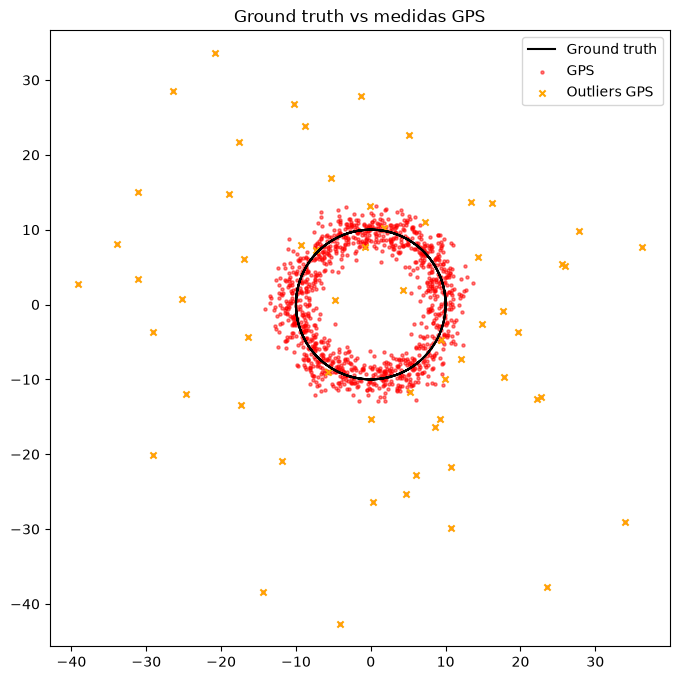

Medidas GPS descartadas por gating: 0 / 1200


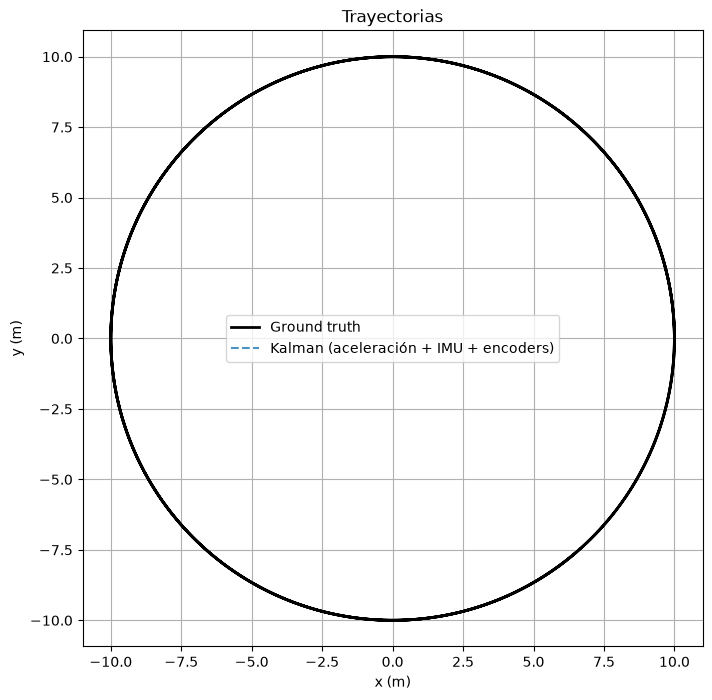

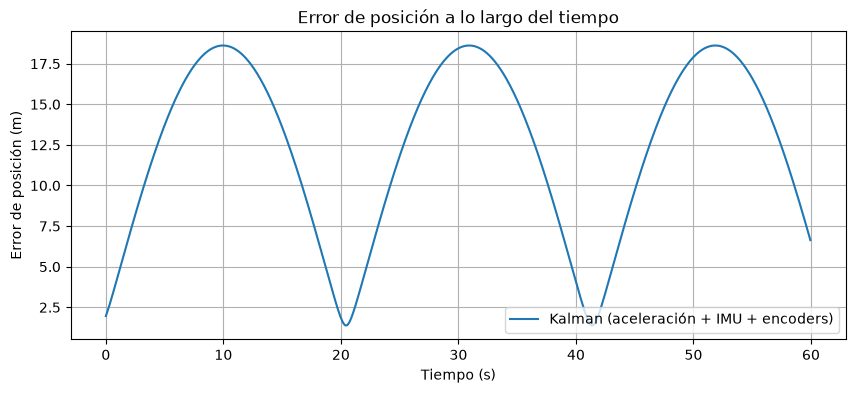

Kalman (aceleración + IMU + encoders)    RMSE=13.486 m  ATE=9.990 m  RPE=1.499 m


In [13]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular')  # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de Kalman con GPS, IMU y encoders
dt = 1.0 / meta['frecuencia_hz']
kalman = KalmanFilterGPSIMUEncoders(
    dt=dt,
    sigma_gps=1.5,
    sigma_imu_a=0.1,
    sigma_imu_w=0.02,
    sigma_enc_v=0.05,
    sigma_enc_w=0.02
)

# Inicializar el estado con la primera medida GPS
kalman.x = np.array([
    medidas['gps']['x_gps'].iloc[0],
    medidas['gps']['y_gps'].iloc[0],
    0.0,   # theta inicial
    0.0,   # v inicial
    0.0    # omega inicial
])

kalman.P = np.diag([4.0, 4.0, 1.0, 1.0, 0.5])

estimates_kf = np.zeros((len(df_gt), 5))
n_descartadas = 0

for i in range(len(df_gt)):
    # Medidas de la IMU
    a_imu = medidas['imu']['ax_imu'].iloc[i]
    omega_imu = medidas['imu']['omega_imu'].iloc[i]

    # Medida GPS
    z_gps = np.array([
        medidas['gps']['x_gps'].iloc[i],
        medidas['gps']['y_gps'].iloc[i]
    ])

    # Medidas de los encoders (convertidas a velocidad)
    v_enc = medidas['encoders']['ds_enc'].iloc[i] / dt
    omega_enc = medidas['encoders']['dtheta_enc'].iloc[i] / dt
    z_enc = (v_enc, omega_enc)

    # Paso del filtro: predicción + gating GPS + actualización encoders
    kalman.predict(a_imu, omega_imu)
    updated = kalman.update_gps_gating(z_gps, umbral=3.0)
    if not updated:
        n_descartadas += 1
    kalman.update_encoders(v_enc, omega_enc)

    estimates_kf[i] = kalman.x.copy()

print(f"Medidas GPS descartadas por gating: {n_descartadas} / {len(df_gt)}")

# 5. Representa el resultado
estimates = {'Kalman (aceleración + IMU + encoders)': estimates_kf}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
# Nota: el ground truth solo tiene [x, y, vx, vy]; comparamos las dos primeras columnas.
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for nombre, est in estimates.items():
    m = summary_metrics(est[:, :4], gt_array, nombre)  # usamos [x, y, v, omega] → ajustar según métrica
    print(f"{m['name']:40s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza la mejoría del filtro de Kalman. ¿Cuánto ha decrecido el error al integrar medidas de otros sensores? ¿El error es adecuado o excesivo para la tarea? ¿Cómo crees que se podría seguir reduciendo?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

### Ejercicio 3: Filtro de Partículas

Implementar un filtro de Partículas para fusionar las medidas del GPS, la IMU y los encoders, obteniendo una localización precisa del robot. 

1. Crea la función de inicialización, que distribuye las partículas alrededor del estado inicial
2. Crea la función de predicción, que propaga las partículas según el modelo y añadiendo ruido
3. Crea la función de actualización, que actualiza los pesos según la verosimilitud de la medida del GPS
4. Crea la función de remuestreo, que filtra las partículas según sus pesos.

In [20]:
class ParticleFilter:
    """
    Filtro de partículas para fusión de GPS + IMU + encoders
    Estado: [x, y, vx, vy]
    """
    def __init__(self, dt, n_particulas=500, sigma_gps=1.5):
        self.dt = dt
        self.N = n_particulas
        self.sigma_gps = sigma_gps
        self.rng = np.random.default_rng(0)
        
        self.particulas = np.zeros((self.N, 4))
        self.pesos = np.ones(self.N) / self.N
    
    def initialize(self, x0):
        """Inicializa partículas alrededor de x0"""
        # TODO: Implementar
        pass
    
    def predict(self, a_imu=None, omega_imu=None):
        """Propaga partículas con el modelo de movimiento + ruido"""
        # TODO: Implementar
        pass
    
    def update(self, z_gps):
        """Actualiza pesos según verosimilitud de la medida GPS"""
        # TODO: Implementar
        pass
    
    def resampling(self):
        """Resampling sistemático"""
        # TODO: Implementar
        pass
    
    def estimate(self):
        """Devuelve la media ponderada de las partículas"""
        return np.average(self.particulas, axis=0, weights=self.pesos)
    
    def step(self, z_gps):
        self.predict()
        if z_gps is not None:
            self.update(z_gps)
            self.resampling()
        return self.estimate()

    def step_with_gating(self, z_gps, umbral=5.0):
        self.predict(a_imu, omega_imu)
        if z_gps is not None:
            # Gating euclídeo: descartar si la medida está muy lejos de la estimación
            estimacion = self.estimate()
            distancia = np.linalg.norm(z_gps[:2] - estimacion[:2])
            if distancia < umbral:
                self.update(z_gps)
                self.resampling()
        return self.estimate()

B) Analiza el rendimiento del filtro de partículas con y sin gating.

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


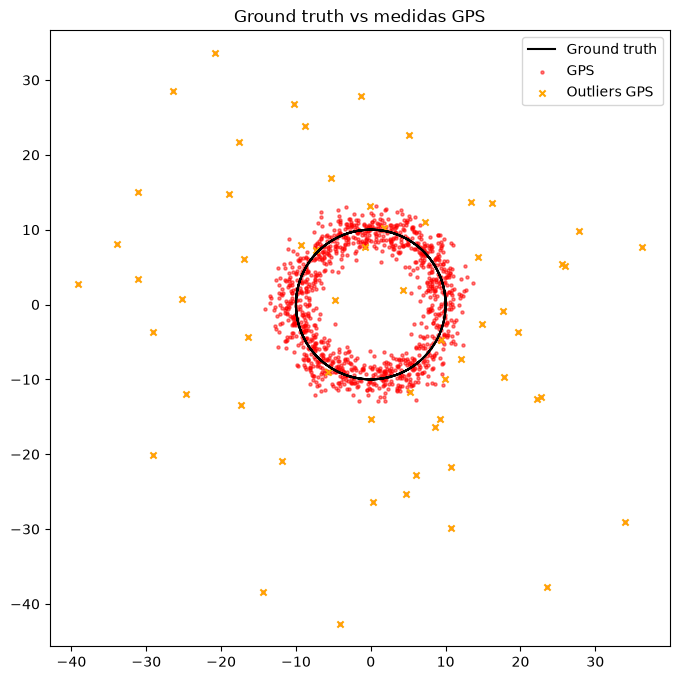

Muestras procesadas: 1200
Muestras procesadas: 1200


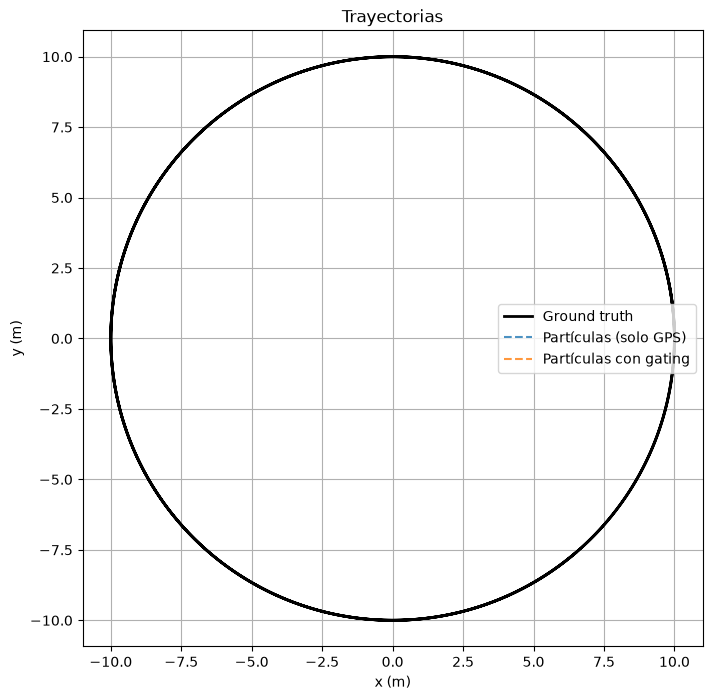

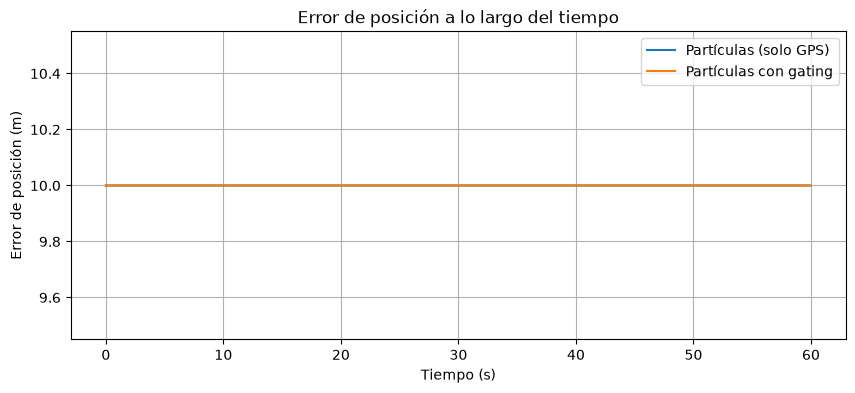

Partículas (solo GPS)          RMSE=10.000 m  ATE=9.990 m  RPE=1.499 m
Partículas con gating          RMSE=10.000 m  ATE=9.990 m  RPE=1.499 m


In [21]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular')  # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de partículas sin gating
dt = 1.0 / meta['frecuencia_hz']

pf = ParticleFilter(
    dt=dt,
    n_particulas=500,
    sigma_gps=1.5
)

# Inicializar las partículas alrededor de la primera medida GPS
pf.initialize(np.array([
    medidas['gps']['x_gps'].iloc[0],
    medidas['gps']['y_gps'].iloc[0],
    0.0,   # vx inicial
    0.0    # vy inicial
]))

estimates_pf = np.zeros((len(df_gt), 4))
n_descartadas = 0

for i in range(len(df_gt)):
    # Medida GPS
    z_gps = np.array([
        medidas['gps']['x_gps'].iloc[i],
        medidas['gps']['y_gps'].iloc[i]
    ])

    # Paso del filtro de partículas
    estimates_pf[i] = pf.step(z_gps)

print(f"Muestras procesadas: {len(df_gt)}")

# 5. Ejecuta el filtro de partículas sin gating
dt = 1.0 / meta['frecuencia_hz']

pf = ParticleFilter(
    dt=dt,
    n_particulas=500,
    sigma_gps=1.5
)

# Inicializar las partículas alrededor de la primera medida GPS
pf.initialize(np.array([
    medidas['gps']['x_gps'].iloc[0],
    medidas['gps']['y_gps'].iloc[0],
    0.0,   # vx inicial
    0.0    # vy inicial
]))

estimates_pf_gating = np.zeros((len(df_gt), 4))
n_descartadas = 0

for i in range(len(df_gt)):
    # Medida GPS
    z_gps = np.array([
        medidas['gps']['x_gps'].iloc[i],
        medidas['gps']['y_gps'].iloc[i]
    ])

    # Paso del filtro de partículas
    estimates_pf_gating[i] = pf.step_with_gating(z_gps)

print(f"Muestras procesadas: {len(df_gt)}")

# 5. Representa el resultado
estimates = {'Partículas (solo GPS)': estimates_pf, 'Partículas con gating': estimates_pf_gating}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for nombre, est in estimates.items():
    m = summary_metrics(est, gt_array, nombre)
    print(f"{m['name']:30s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza los resultados del filtro de partículas. ¿El gating es interesante? ¿Cuál es su rendimiento en comparación con el filtro de Kalman? ¿Por qué crees que ocurre esto?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.